In [ ]:
initial_state = (
    1, 2, 3,
    0, 4, 6,
    7, 5, 8
)

goal_state = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

def display(state):
    for i in range(0, 9, 3):
        print(*state[i:i+3])
    print()

In [ ]:
def get_neighbors(state):
    neighbors = []

    blank = state.index(0)
    row, col = divmod(blank, 3)

    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    for dr, dc, action in moves:
        nr, nc = row + dr, col + dc

        if 0 <= nr < 3 and 0 <= nc < 3:
            new_blank = nr * 3 + nc
            board = list(state)

            board[blank], board[new_blank] = (
                board[new_blank], board[blank]
            )

            neighbors.append((tuple(board), action))

    return neighbors

In [ ]:
def depth_limited_search(state, goal, limit, path_states):
    if state == goal:
        return []

    if limit == 0:
        return None

    for next_state, action in get_neighbors(state):
        if next_state in path_states:
            continue

        path_states.add(next_state)

        result = depth_limited_search(
            next_state,
            goal,
            limit - 1,
            path_states
        )

        path_states.remove(next_state)

        if result is not None:
            return [(action, next_state)] + result

    return None

In [ ]:
def ids(initial, goal, max_depth=50):
    for depth in range(max_depth + 1):
        print(f"Searching at depth limit: {depth}")

        result = depth_limited_search(
            initial,
            goal,
            depth,
            {initial}
        )

        if result is not None:
            return result

    return None

In [ ]:
solution = ids(initial_state, goal_state)

if solution is None:
    print("No solution found within the maximum depth.")
else:
    print("\nSolution found!")
    print("Initial State:")
    display(initial_state)

    for step, (action, state) in enumerate(solution, start=1):
        print(f"Step {step}: Move blank {action}")
        display(state)

    print("Total moves:", len(solution))

Searching at depth limit: 0
Searching at depth limit: 1
Searching at depth limit: 2
Searching at depth limit: 3

Solution found!
Initial State:
1 2 3
0 4 6
7 5 8

Step 1: Move blank RIGHT
1 2 3
4 0 6
7 5 8

Step 2: Move blank DOWN
1 2 3
4 5 6
7 0 8

Step 3: Move blank RIGHT
1 2 3
4 5 6
7 8 0

Total moves: 3


In [ ]:
from graphviz import Digraph

def ids_visual(initial, goal, max_depth=30):
    graph = Digraph("IDS")
    graph.attr(rankdir="TB", size="14,10")
    graph.attr("node", shape="box", fontname="monospace")

    solution = None
    total_visits = 0
    final_nodes = set()
    final_edges = []

    def label(state):
        return (
            f"{state[0]} {state[1]} {state[2]}\n"
            f"{state[3]} {state[4]} {state[5]}\n"
            f"{state[6]} {state[7]} {state[8]}"
        )

    for limit in range(max_depth + 1):
        print(f"Depth limit = {limit}")
        visited_this_iteration = set()
        edges_this_iteration = []
        path_states = {initial}

        def dls(state, depth):
            nonlocal total_visits
            total_visits += 1
            visited_this_iteration.add(state)

            if state == goal:
                return []

            if depth == limit:
                return None

            for nxt, action in get_neighbors(state):
                if nxt in path_states:
                    continue

                path_states.add(nxt)
                result = dls(nxt, depth + 1)
                path_states.remove(nxt)

                edges_this_iteration.append((state, nxt, action))

                if result is not None:
                    return [(action, nxt)] + result

            return None

        result = dls(initial, 0)

        # Store the last iteration's graph for display.
        # Each iteration restarts from the initial state.
        final_nodes = visited_this_iteration
        final_edges = edges_this_iteration

        if result is not None:
            solution = result
            break

    for state in final_nodes:
        attrs = {"label": label(state)}

        if state == initial:
            attrs.update(style="filled", fillcolor="lightblue")
        elif state == goal:
            attrs.update(style="filled", fillcolor="lightgreen")

        graph.node(str(state), **attrs)

    for src, dst, action in final_edges:
        graph.edge(str(src), str(dst), label=action, color="gray")

    if solution is not None:
        current = initial

        for action, nxt in solution:
            graph.edge(
                str(current), str(nxt),
                label=action,
                color="green",
                penwidth="3"
            )
            current = nxt

    print("Total recursive visits across iterations:", total_visits)
    print("Solution found:", solution is not None)

    return graph, solution

Depth limit = 0
Depth limit = 1
Depth limit = 2
Depth limit = 3
Total recursive visits across iterations: 30
Solution found: True


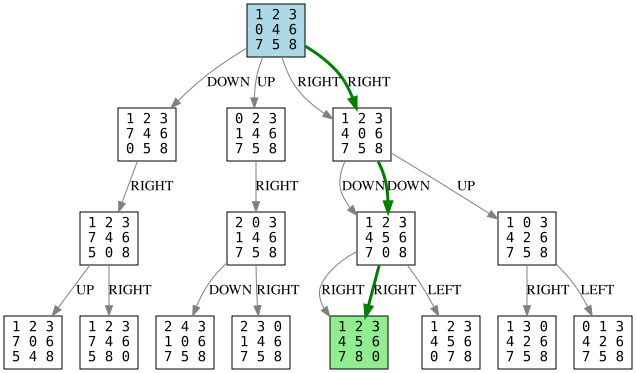

In [ ]:
graph, solution = ids_visual(
    initial_state,
    goal_state,
    max_depth=30
)

graph